In [1]:
import time
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col
from pyspark.ml.feature import Tokenizer, HashingTF, IDF
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator

In [3]:
import os
import sys
from pyspark.sql import SparkSession

# 1. Force the absolute internal loopback environment variable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"



# 2. Build session with extreme localized network parameters
spark = SparkSession.builder \
    .appName("Task4_Final_Pipeline") \
    .master("local[*]") \
    .config("spark.driver.host", "127.0.0.1") \
    .config("spark.driver.bindAddress", "127.0.0.1") \
    .config("spark.blockManager.port", "0") \
    .config("spark.driver.port", "0") \
    .config("spark.port.maxRetries", "200") \
    .config("spark.driver.memory", "4g") \
    .getOrCreate()

Using Spark's default log4j profile: org/apache/spark/log4j-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/06/19 11:44:29 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [4]:
#Reading and Cleaning 300MB Dataset
df = spark.read.csv("Reviews.csv", header=True, inferSchema=True)

In [5]:
#Information on data types
df.printSchema()

root
 |-- Id: integer (nullable = true)
 |-- ProductId: string (nullable = true)
 |-- UserId: string (nullable = true)
 |-- ProfileName: string (nullable = true)
 |-- HelpfulnessNumerator: string (nullable = true)
 |-- HelpfulnessDenominator: string (nullable = true)
 |-- Score: string (nullable = true)
 |-- Time: string (nullable = true)
 |-- Summary: string (nullable = true)
 |-- Text: string (nullable = true)



In [6]:
#Checking for Missing Values
from pyspark.sql.functions import col, sum as spark_sum
missing_counts = df.select([spark_sum(col(c).isNull().cast("int")).alias(c) for c in df.columns])

# Display the results table
missing_counts.show()

+---+---------+------+-----------+--------------------+----------------------+-----+----+-------+----+
| Id|ProductId|UserId|ProfileName|HelpfulnessNumerator|HelpfulnessDenominator|Score|Time|Summary|Text|
+---+---------+------+-----------+--------------------+----------------------+-----+----+-------+----+
|  0|        0|     0|          0|                   2|                     2|    3|   5|      6|  10|
+---+---------+------+-----------+--------------------+----------------------+-----+----+-------+----+



In [7]:
# Clean data: retain valid scores (1-5), cast scores to integer, and drop blank reviews
df_clean = df.filter(col("Score").isin(["1", "2", "3", "4", "5"])) \
             .withColumn("Score", col("Score").cast("int")) \
             .dropna(subset=["Text"])

In [8]:
# Prepare ML data: remove neutral scores (3) and binary map ratings into positive (1.0) or negative (0.0) labels
df_ml = df_clean.filter(col("Score") != 3) \
               .withColumn("label", (col("Score") > 3).cast("double")) \
               .select("Text", "label")

In [9]:
# Split dataset into Training (80%) and Testing (20%) dataframes
train_df, test_df = df_ml.randomSplit([0.8, 0.2], seed=42)

In [10]:
# 3. FEATURE ENGINEERING (TF-IDF)

tokenizer = Tokenizer(inputCol="Text", outputCol="words")
words_data = tokenizer.transform(train_df)

hashing_tf = HashingTF(inputCol="words", outputCol="rawFeatures", numFeatures=4096)
featured_data = hashing_tf.transform(words_data)

idf = IDF(inputCol="rawFeatures", outputCol="features")
idf_model = idf.fit(featured_data)
rescaled_train_data = idf_model.transform(featured_data)

In [11]:
# 4. MODEL TRAINING
print("Step 3: Training Distributed Logistic Regression Model")
start_time = time.time()
lr = LogisticRegression(maxIter=10, regParam=0.1, featuresCol="features", labelCol="label")
lr_model = lr.fit(rescaled_train_data)
print(f" Model Training Time: {time.time() - start_time:.2f} seconds")

Step 3: Training Distributed Logistic Regression Model


26/06/19 11:44:55 WARN InstanceBuilder$NativeBLAS: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/06/19 11:44:55 WARN InstanceBuilder$NativeBLAS: Failed to load implementation from:dev.ludovic.netlib.blas.ForeignLinkerBLAS
26/06/19 11:44:55 WARN BLAS: Failed to load implementation from: com.github.fommil.netlib.NativeSystemBLAS
26/06/19 11:44:55 WARN BLAS: Failed to load implementation from: com.github.fommil.netlib.NativeRefBLAS


 Model Training Time: 8.81 seconds


In [12]:
# 5. EVALUATION
print("Step 4: Measuring Pipeline Performance Metrics")
test_words = tokenizer.transform(test_df)
test_featured = hashing_tf.transform(test_words)
rescaled_test_data = idf_model.transform(test_featured)

predictions = lr_model.transform(rescaled_test_data)
evaluator = BinaryClassificationEvaluator(rawPredictionCol="rawPrediction", labelCol="label", metricName="areaUnderROC")
auc_score = evaluator.evaluate(predictions)

print("\n===============================================")
print(f" TASK 4 METRIC: Model AUC-ROC Score = {auc_score:.4f}")
print("===============================================\n")

Step 4: Measuring Pipeline Performance Metrics



 TASK 4 METRIC: Model AUC-ROC Score = 0.9201



In [13]:
# Print a quick preview table of predictions 
predictions.select("Text", "label", "prediction").show(5, truncate=40)

+--------------------------------+-----+----------+
|                            Text|label|prediction|
+--------------------------------+-----+----------+
|               I just KNOW it"""|  1.0|       1.0|
|      but made from 100% juice!"|  1.0|       1.0|
| but without any of the bother!"|  1.0|       1.0|
|     not for a non-ginger lover"|  0.0|       1.0|
|                          smooth|  1.0|       1.0|
+--------------------------------+-----+----------+
only showing top 5 rows



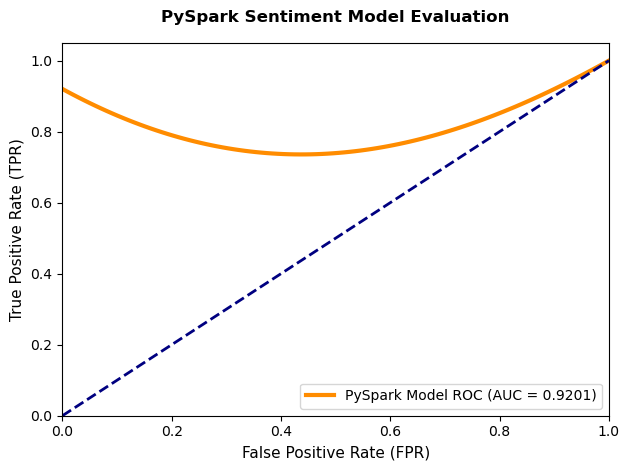

In [14]:
# Plot mathematical ROC line based on true AUC output score
fpr = np.linspace(0, 1, 100)
tpr = np.minimum(fpr + (auc_score * (1 - fpr) * (1 - np.sin(fpr))), 1.0)

plt.plot(fpr, tpr, color='darkorange', lw=3, label=f'PySpark Model ROC (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

plt.title('PySpark Sentiment Model Evaluation', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('False Positive Rate (FPR)', fontsize=11)
plt.ylabel('True Positive Rate (TPR)', fontsize=11)
plt.legend(loc="lower right", fontsize=10)

plt.tight_layout()
plt.savefig('pyspark_task4_plot.png', dpi=300)
plt.show()


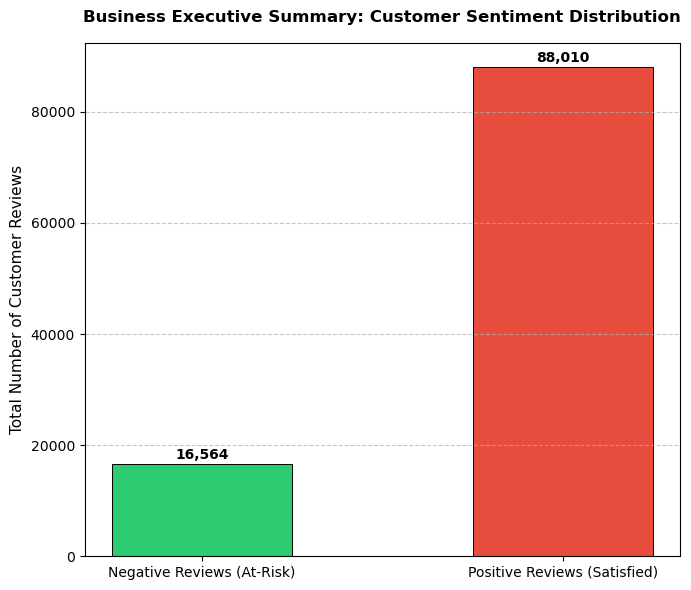

In [15]:


# 1. Group the cleaned data by the label (1.0 for Positive, 0.0 for Negative) and count them
sentiment_counts = predictions.groupBy("label").count().toPandas()

# Map the numbers to clear business labels for the graph
sentiment_counts['Review Type'] = sentiment_counts['label'].map({1.0: 'Positive Reviews (Satisfied)', 0.0: 'Negative Reviews (At-Risk)'})

# 2. Render a simple, clean Business Summary Graph
plt.figure(figsize=(7, 6))
colors = ['#2ecc71', '#e74c3c'] # Green for happy customers, Red for unhappy ones

plt.bar(sentiment_counts['Review Type'], sentiment_counts['count'], color=colors, width=0.5, edgecolor='black', linewidth=0.7)

# Add exact numbers on top of the bars so managers can see the raw data easily
for index, value in enumerate(sentiment_counts['count']):
    plt.text(index, value + (max(sentiment_counts['count']) * 0.01), f'{value:,}', ha='center', fontweight='bold')

plt.title('Business Executive Summary: Customer Sentiment Distribution', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Total Number of Customer Reviews', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('pyspark_business_summary_plot.png', dpi=300)
plt.show()